# 01 · Data exploration

Measured daily air-quality data for six Indian cities, 2018–2024.

**Sources**
- Pollutants: XKDR Forum, *India Air Quality Database* (https://airquality.xkdr.org), compiled from the CPCB CAAQM continuous monitoring network. CC BY 4.0.
- Weather: Open-Meteo Historical Weather API (ERA5 reanalysis). CC BY 4.0.

**Pipeline** (run from `air_quality_prediction/`):
```
python scripts/fetch_data.py      # needs XKDR_API_KEY
python scripts/build_dataset.py
```
`build_dataset.py` averages stations to city-day values, computes the CPCB National AQI, joins weather and builds features. The target is **next-day AQI**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/processed/aqi_daily_features.csv", parse_dates=["date"])
print(df.shape)
df.groupby("city")["date"].agg(["min", "max", "count"])

(14999, 96)


,min,max,count
city,,,
Bengaluru,2018-01-01,2024-12-30,2546
Chennai,2018-01-01,2024-12-30,2556
Delhi,2018-01-01,2024-12-30,2556
Hyderabad,2018-01-01,2024-12-30,2556
Kolkata,2018-04-11,2024-12-30,2395
Mumbai,2018-05-07,2024-12-30,2390


## Missing data
Share of city-days with no valid value (after the 16-hour completeness rule).

In [2]:
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "SO2", "CO", "O3", "Benzene", "Toluene"]
weather = ["temperature", "humidity", "wind_speed", "wind_direction", "pressure", "precipitation"]
(df.groupby("city")[pollutants + weather].apply(lambda g: g.isna().mean() * 100)).round(1)

,PM2.5,PM10,NO,NO2,NOx,NH3,SO2,CO,O3,Benzene,Toluene,temperature,humidity,wind_speed,wind_direction,pressure,precipitation
city,,,,,,,,,,,,,,,,,
Bengaluru,0.6,1.0,0.0,0.0,0.0,4.9,0.0,0.0,0.9,0.9,0.9,0.0,0.0,0.0,0.0,0.0,0.0
Chennai,0.0,24.6,0.0,0.0,0.0,1.3,0.1,0.0,0.5,0.5,0.5,0.0,0.0,0.0,0.0,0.0,0.0
Delhi,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Hyderabad,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Kolkata,0.0,0.0,0.1,0.1,0.0,0.0,0.3,0.0,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Mumbai,0.0,1.4,1.1,1.2,0.3,14.8,0.1,0.1,0.0,0.2,36.9,0.0,0.0,0.0,0.0,0.0,0.0


## AQI over time

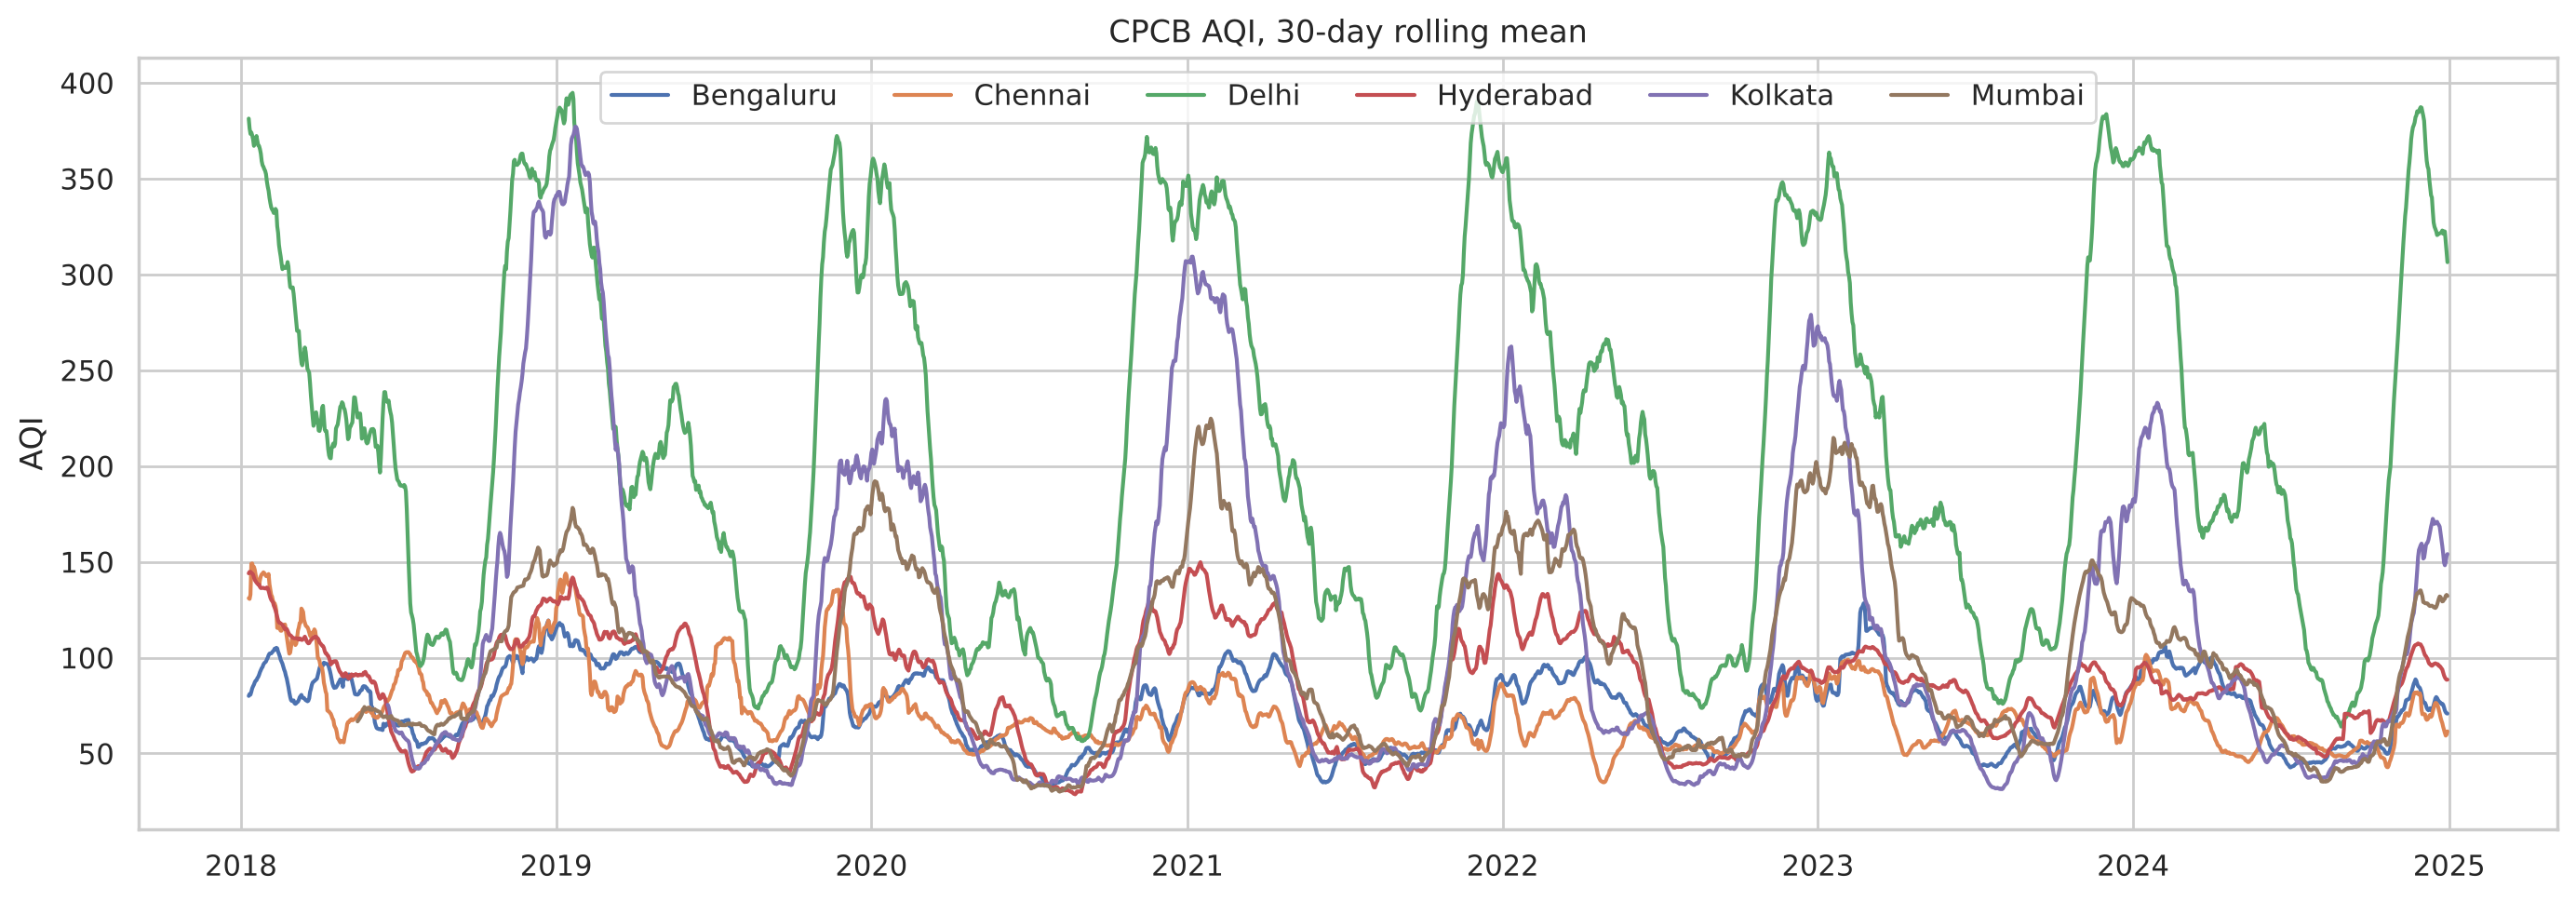

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))
for c, g in df.groupby("city"):
    ax.plot(g["date"], g["AQI"].rolling(30, min_periods=10).mean(), label=c)
ax.set(title="CPCB AQI, 30-day rolling mean", ylabel="AQI")
ax.legend(ncol=6)
plt.tight_layout(); plt.savefig("../results/plots/aqi_timeseries.png", dpi=150)

## Seasonality
Winter (Nov–Jan) peaks in the north, monsoon lows everywhere.

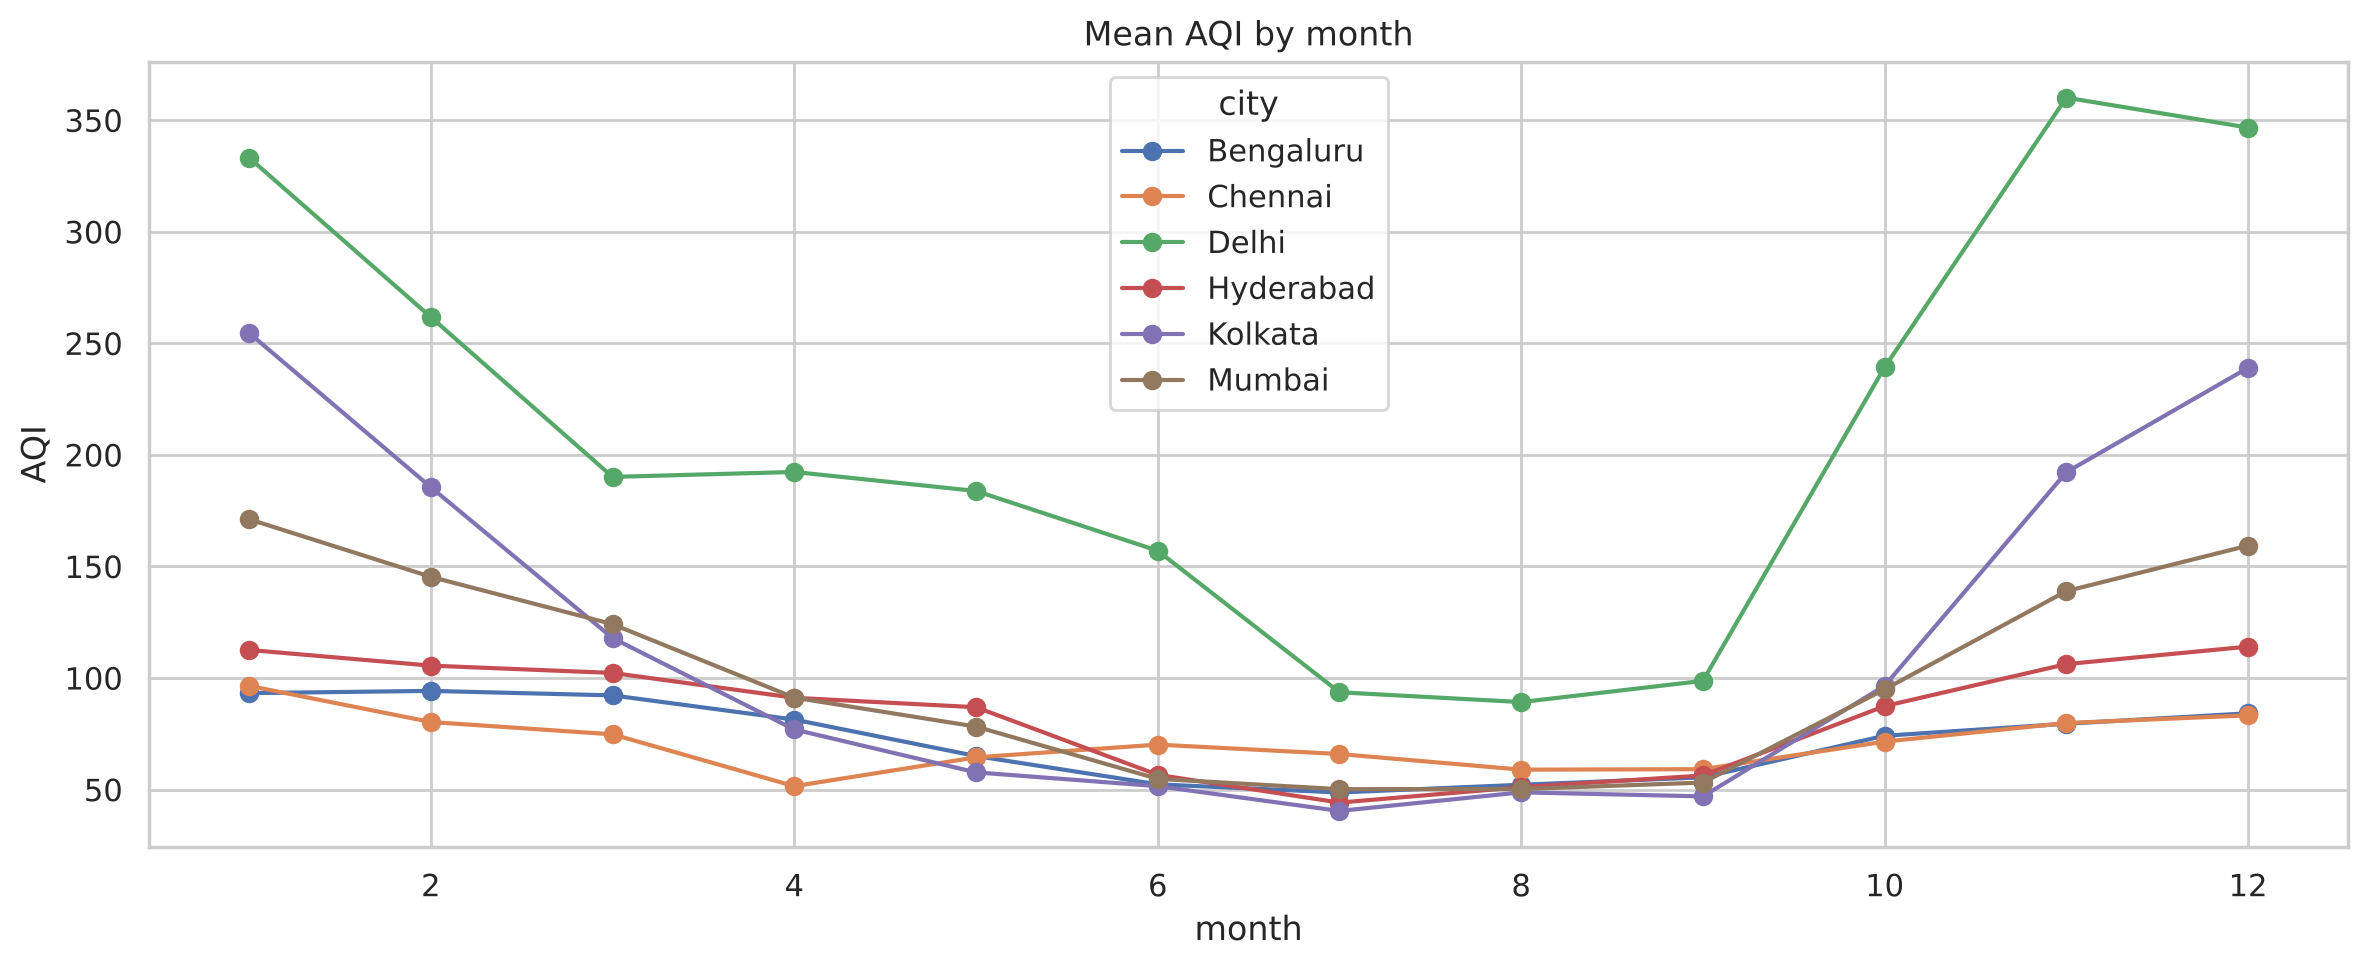

In [4]:
m = df.groupby(["city", "month"])["AQI"].mean().unstack("city")
ax = m.plot(figsize=(12, 5), marker="o", title="Mean AQI by month")
ax.set_ylabel("AQI")
plt.tight_layout(); plt.savefig("../results/plots/aqi_by_month.png", dpi=150)

## Prominent pollutant
Which pollutant sets the AQI on each day.

In [5]:
pd.crosstab(df["city"], df["prominent_pollutant"], normalize="index").mul(100).round(1)

prominent_pollutant,CO,NO2,O3,PM10,PM2.5,SO2
city,,,,,,
Bengaluru,4.6,0.5,1.0,86.6,7.3,0.0
Chennai,14.0,0.2,7.5,49.8,28.4,0.0
Delhi,1.2,0.0,0.1,51.7,47.0,0.0
Hyderabad,0.8,3.2,0.5,85.3,10.2,0.0
Kolkata,2.3,1.6,5.5,57.5,33.1,0.0
Mumbai,8.9,0.1,0.3,74.1,16.1,0.5


## Correlation with next-day AQI

AQI               0.930
PM10              0.910
PM2.5             0.891
NO2               0.743
NOx               0.716
NO                0.687
CO                0.679
Toluene           0.577
NH3               0.474
SO2               0.426
Benzene           0.374
O3                0.219
pressure          0.201
wind_direction    0.158
precipitation    -0.248
wind_speed       -0.316
humidity         -0.341
temperature      -0.463
Name: target_AQI_next_day, dtype: float64

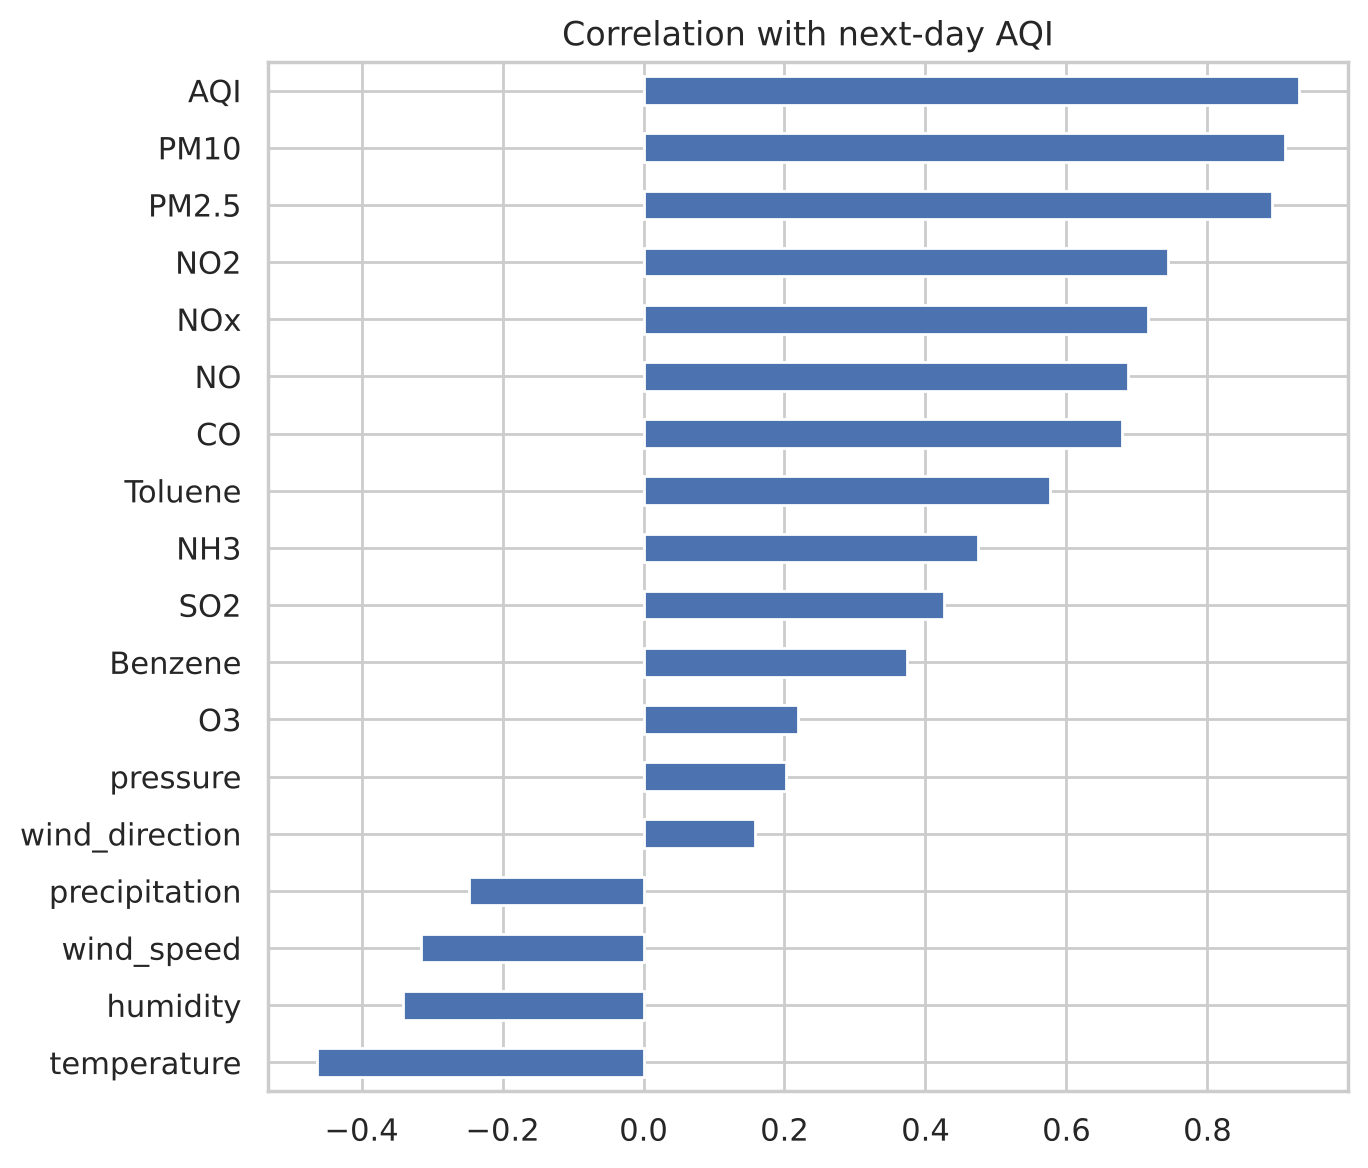

In [6]:
cols = pollutants + weather + ["AQI"]
corr = df[cols + ["target_AQI_next_day"]].corr()["target_AQI_next_day"].drop("target_AQI_next_day")
corr.sort_values().plot.barh(figsize=(7, 6), title="Correlation with next-day AQI")
plt.tight_layout(); plt.savefig("../results/plots/target_correlation.png", dpi=150)
corr.sort_values(ascending=False).round(3)